In [18]:
!pip install -q kaggle

In [19]:
from google.colab import userdata
import os

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

In [20]:
!mkdir -p /content/PlantLeafNet

!kaggle datasets download \
    -d abdallahalidev/plantvillage-dataset \
    -p /content/PlantLeafNet

Dataset URL: https://www.kaggle.com/datasets/abdallahalidev/plantvillage-dataset
License(s): CC-BY-NC-SA-4.0
100% 2.04G/2.04G [01:59<00:00, 18.3MB/s]



In [21]:
import zipfile
from pathlib import Path

zip_files = list(Path("/content/PlantLeafNet").glob("*.zip"))

with zipfile.ZipFile(zip_files[0], "r") as zip_ref:
    zip_ref.extractall("/content/PlantLeafNet")

print("Dataset extracted!")

Dataset extracted!


In [11]:
import torch
import torch.nn as nn
import torch.optim as optim

import pandas as pd
import numpy as np

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

import matplotlib.pyplot as plt

print("Libraries imported successfully!")
print("PyTorch version:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0))

Libraries imported successfully!
PyTorch version: 2.11.0+cu130
GPU: Tesla T4


In [22]:
import pandas as pd

SPLIT_DIR = "/content/PlantLeafNet/splits"

train_df = pd.read_csv(f"{SPLIT_DIR}/train.csv")
val_df = pd.read_csv(f"{SPLIT_DIR}/validation.csv")
test_df = pd.read_csv(f"{SPLIT_DIR}/test.csv")

print(len(train_df), len(val_df), len(test_df))

37998 8142 8143


In [23]:
from pathlib import Path

BASE_DIR = Path("/content/PlantLeafNet")

color_dirs = [
    p for p in BASE_DIR.rglob("color")
    if p.is_dir() and any(x.is_dir() for x in p.iterdir())
]

print("Color directories found:", color_dirs)

Color directories found: [PosixPath('/content/PlantLeafNet/plantvillage dataset/color')]


In [24]:
COLOR_DIR = color_dirs[0]

for df in [train_df, val_df, test_df]:

    df["Image_Path"] = df["Image_Path"].apply(
        lambda old_path: str(
            COLOR_DIR / Path(old_path).parent.name / Path(old_path).name
        )
    )

In [25]:
from pathlib import Path

for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    missing = sum(
        not Path(p).is_file()
        for p in df["Image_Path"]
    )

    print(f"{name}: {missing} missing images out of {len(df)}")

Train: 0 missing images out of 37998
Validation: 0 missing images out of 8142
Test: 0 missing images out of 8143


In [26]:
train_df.to_csv(f"{SPLIT_DIR}/train.csv", index=False)
val_df.to_csv(f"{SPLIT_DIR}/validation.csv", index=False)
test_df.to_csv(f"{SPLIT_DIR}/test.csv", index=False)

In [27]:
classes = sorted(train_df["Class"].unique())

class_to_idx = {
    name: idx for idx, name in enumerate(classes)
}

print("Number of classes:", len(classes))

Number of classes: 38


In [28]:
class PlantDataset(Dataset):

    def __init__(self, dataframe, class_to_idx, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.class_to_idx = class_to_idx
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image = Image.open(row["Image_Path"]).convert("RGB")
        label = self.class_to_idx[row["Class"]]

        if self.transform:
            image = self.transform(image)

        return image, label

In [29]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

train_dataset = PlantDataset(train_df, class_to_idx, train_transform)
val_dataset = PlantDataset(val_df, class_to_idx, train_transform)
test_dataset = PlantDataset(test_df, class_to_idx, train_transform)

train_loader = DataLoader(
    train_dataset, batch_size=32, shuffle=True, num_workers=2
)

val_loader = DataLoader(
    val_dataset, batch_size=32, shuffle=False, num_workers=2
)

test_loader = DataLoader(
    test_dataset, batch_size=32, shuffle=False, num_workers=2
)

In [30]:
images, labels = next(iter(train_loader))

print("Images:", images.shape)
print("Labels:", labels.shape)
print("Classes:", len(classes))
print("Device:", torch.cuda.get_device_name(0))

Images: torch.Size([32, 3, 224, 224])
Labels: torch.Size([32])
Classes: 38
Device: Tesla T4


In [31]:
class PlantCNN(nn.Module):

    def __init__(self, num_classes=38):
        super().__init__()

        self.features = nn.Sequential(

            # Block 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = self.classifier(x)
        return x

In [32]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = PlantCNN(num_classes=38).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Training device:", device)
print("Model parameters:", sum(p.numel() for p in model.parameters()))

Training device: cuda
Model parameters: 98598


In [33]:
from tqdm.auto import tqdm

model.train()

running_loss = 0.0
correct = 0
total = 0

for images, labels in tqdm(train_loader):

    images = images.to(device)
    labels = labels.to(device)

    # Forward pass
    outputs = model(images)

    # Calculate loss
    loss = criterion(outputs, labels)

    # Backpropagation
    optimizer.zero_grad()
    loss.backward()

    # Update weights
    optimizer.step()

    running_loss += loss.item()

    predictions = outputs.argmax(dim=1)

    total += labels.size(0)
    correct += (predictions == labels).sum().item()

epoch_loss = running_loss / len(train_loader)
epoch_accuracy = 100 * correct / total

print(f"Training Loss: {epoch_loss:.4f}")
print(f"Training Accuracy: {epoch_accuracy:.2f}%")

  0%|          | 0/1188 [00:00<?, ?it/s]

Training Loss: 1.5429
Training Accuracy: 57.45%


In [34]:
def train_one_epoch(model, train_loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        total += labels.size(0)
        correct += (predictions == labels).sum().item()

    epoch_loss = running_loss / len(train_loader)
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy

In [35]:
def validate_one_epoch(model, val_loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item()

            predictions = outputs.argmax(dim=1)

            total += labels.size(0)
            correct += (predictions == labels).sum().item()

    epoch_loss = running_loss / len(val_loader)
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy

In [36]:
history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

best_val_accuracy = 0.0
EPOCHS = 5

MODEL_PATH = "/content/PlantLeafNet/best_cnn_baseline.pth"

In [37]:
from tqdm.auto import tqdm

for epoch in range(EPOCHS):

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    # Training
    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    # Validation
    val_loss, val_accuracy = validate_one_epoch(
        model,
        val_loader,
        criterion,
        device
    )

    # Save metrics
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)

    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_accuracy:.2f}%")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.2f}%")

    # Save best model
    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        torch.save(
            model.state_dict(),
            MODEL_PATH
        )

        print("Best model saved!")

print("\nTraining completed!")
print("Best Validation Accuracy:", best_val_accuracy)


Epoch 1/5


Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78575c8ddf80>Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78575c8ddf80>

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    AssertionErrorself._shutdown_workers(): 
can only test a child process
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a chi

Train Loss: 0.9323
Train Accuracy: 72.40%
Validation Loss: 0.7780
Validation Accuracy: 75.67%
Best model saved!

Epoch 2/5
Train Loss: 0.7345
Train Accuracy: 77.91%
Validation Loss: 0.7488
Validation Accuracy: 75.95%
Best model saved!

Epoch 3/5
Train Loss: 0.6352
Train Accuracy: 80.72%
Validation Loss: 0.4999
Validation Accuracy: 84.78%
Best model saved!

Epoch 4/5
Train Loss: 0.5602
Train Accuracy: 82.90%
Validation Loss: 0.7164
Validation Accuracy: 77.46%

Epoch 5/5
Train Loss: 0.5187
Train Accuracy: 83.88%
Validation Loss: 0.9662
Validation Accuracy: 70.29%

Training completed!
Best Validation Accuracy: 84.78260869565217


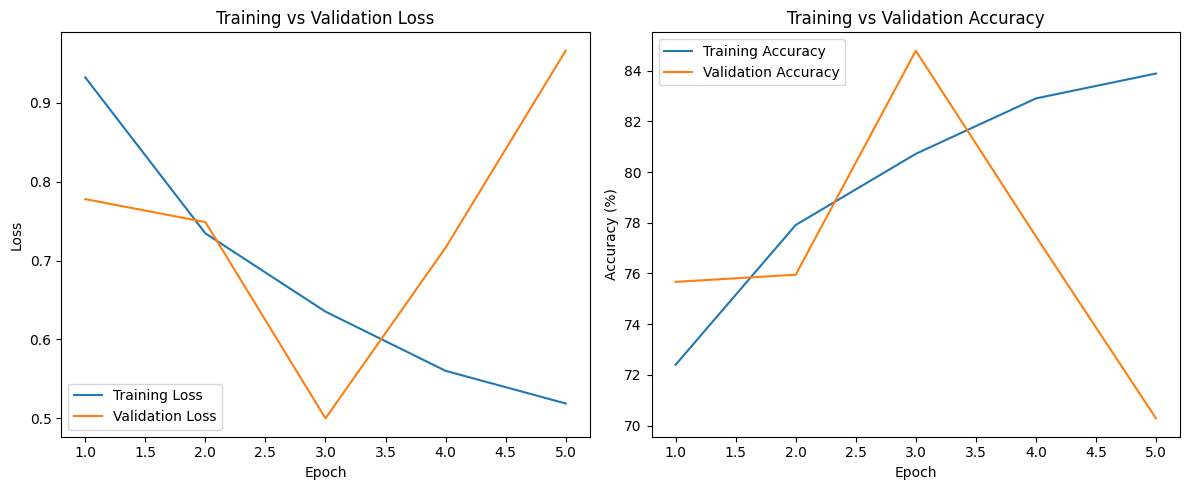

In [38]:
epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(epochs_range, history["train_loss"], label="Training Loss")
plt.plot(epochs_range, history["val_loss"], label="Validation Loss")

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(epochs_range, history["train_accuracy"], label="Training Accuracy")
plt.plot(epochs_range, history["val_accuracy"], label="Validation Accuracy")

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()

plt.tight_layout()
plt.show()

In [39]:
checkpoint = torch.load(
    MODEL_PATH,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint)

print("Best checkpoint loaded successfully!")

Best checkpoint loaded successfully!


In [40]:
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    confusion_matrix
)

model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predictions.cpu().numpy())

print("Predictions collected:", len(all_predictions))

Predictions collected: 8142


In [41]:
accuracy = accuracy_score(all_labels, all_predictions)

print(f"Validation Accuracy: {accuracy * 100:.2f}%")

Validation Accuracy: 84.78%


In [42]:
report = classification_report(
    all_labels,
    all_predictions,
    target_names=classes,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

report_df.round(3)

,precision,recall,f1-score,support
Apple___Apple_scab,0.768,0.558,0.646,95.000
Apple___Black_rot,0.592,0.903,0.715,93.000
Apple___Cedar_apple_rust,1.000,0.537,0.698,41.000
Apple___healthy,0.886,0.796,0.839,245.000
Blueberry___healthy,0.815,0.960,0.882,225.000
Cherry_(including_sour)___Powdery_mildew,0.837,0.880,0.858,158.000
Cherry_(including_sour)___healthy,0.589,0.930,0.721,128.000
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,0.935,0.558,0.699,77.000
Corn_(maize)___Common_rust_,1.000,1.000,1.000,179.000
Corn_(maize)___Northern_Leaf_Blight,0.816,0.838,0.827,148.000


In [43]:
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=range(len(classes))
)

# Find the index of Grape healthy
grape_idx = class_to_idx["Grape___healthy"]

# Get predictions for actual Grape healthy images
grape_predictions = cm[grape_idx]

# Convert prediction counts into a readable table
grape_confusion = pd.DataFrame({
    "Predicted Class": classes,
    "Images": grape_predictions
})

grape_confusion = grape_confusion[
    grape_confusion["Images"] > 0
].sort_values("Images", ascending=False)

grape_confusion

,Predicted Class,Images
24,Soybean___healthy,26
6,Cherry_(including_sour)___healthy,21
19,"Pepper,_bell___healthy",9
14,Grape___healthy,6
15,Orange___Haunglongbing_(Citrus_greening),2


In [44]:
# Find validation images that were actually Grape healthy
# but predicted as another class

grape_mistakes = []

for i, (actual, predicted) in enumerate(
    zip(all_labels, all_predictions)
):
    if actual == grape_idx and actual != predicted:
        row = val_df.iloc[i]

        grape_mistakes.append({
            "Image_Path": row["Image_Path"],
            "Actual": classes[actual],
            "Predicted": classes[predicted]
        })

grape_mistakes_df = pd.DataFrame(grape_mistakes)

print("Misclassified Grape healthy images:",
      len(grape_mistakes_df))

grape_mistakes_df.head()

Misclassified Grape healthy images: 58


,Image_Path,Actual,Predicted
0,/content/PlantLeafNet/plantvillage dataset/col...,Grape___healthy,Soybean___healthy
1,/content/PlantLeafNet/plantvillage dataset/col...,Grape___healthy,Cherry_(including_sour)___healthy
2,/content/PlantLeafNet/plantvillage dataset/col...,Grape___healthy,Soybean___healthy
3,/content/PlantLeafNet/plantvillage dataset/col...,Grape___healthy,Soybean___healthy
4,/content/PlantLeafNet/plantvillage dataset/col...,Grape___healthy,Soybean___healthy


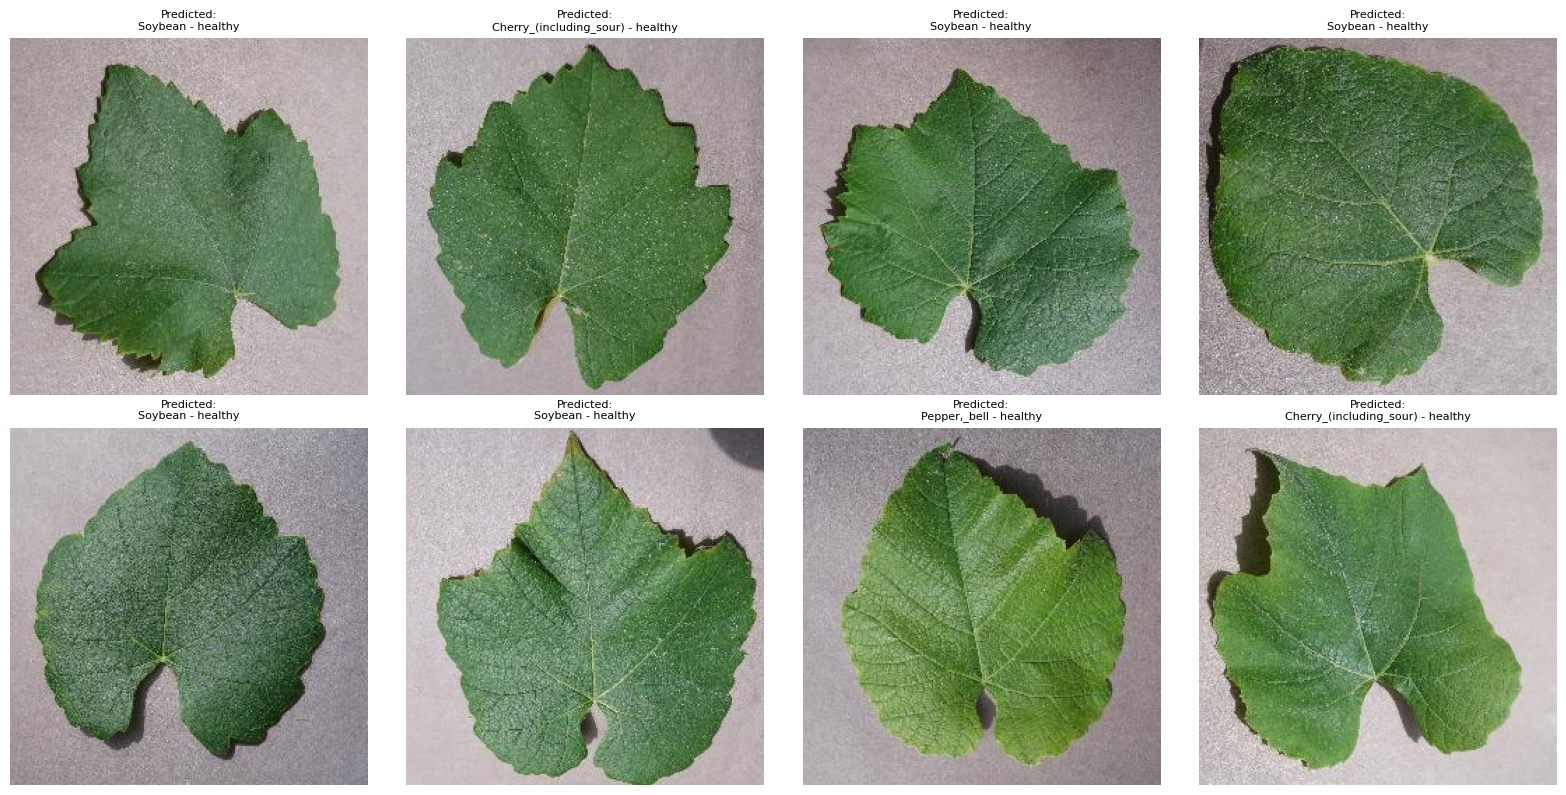

In [45]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, (_, row) in zip(
    axes.flat,
    grape_mistakes_df.head(8).iterrows()
):
    image = Image.open(row["Image_Path"]).convert("RGB")

    ax.imshow(image)
    ax.set_title(
        f"Predicted:\n{row['Predicted'].replace('___', ' - ')}",
        fontsize=8
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [46]:
train_df[
    train_df["Class"] == "Grape___healthy"
].shape[0]

296

In [47]:
important_classes = [
    "Grape___healthy",
    "Soybean___healthy",
    "Cherry_(including_sour)___healthy",
    "Pepper,_bell___healthy"
]

train_df["Class"].value_counts().reindex(important_classes)

,count
Class,
Grape___healthy,296
Soybean___healthy,3563
Cherry_(including_sour)___healthy,598
"Pepper,_bell___healthy",1035


In [49]:
# Count training examples for each class
class_counts = train_df["Class"].value_counts()

# Calculate inverse-frequency weights
num_samples = len(train_df)
num_classes = len(classes)

class_weights = []

for class_name in classes:
    count = class_counts[class_name]
    weight = num_samples / (num_classes * count)
    class_weights.append(weight)

# Convert weights into a PyTorch tensor
class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

print("Number of class weights:", len(class_weights))
print("Grape healthy weight:",
      class_weights[class_to_idx["Grape___healthy"]].item())
print("Soybean healthy weight:",
      class_weights[class_to_idx["Soybean___healthy"]].item())

Number of class weights: 38
Grape healthy weight: 3.3782005310058594
Soybean healthy weight: 0.2806476056575775


In [50]:
criterion_weighted = nn.CrossEntropyLoss(
    weight=class_weights
)

In [51]:
torch.manual_seed(42)

weighted_model = PlantCNN(
    num_classes=38
).to(device)

weighted_optimizer = optim.Adam(
    weighted_model.parameters(),
    lr=0.001
)

print("Weighted CNN initialized!")

Weighted CNN initialized!


In [53]:
# Reset history for the weighted experiment
weighted_history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

weighted_best_val_accuracy = 0.0

EPOCHS = 5

WEIGHTED_MODEL_PATH = "/content/PlantLeafNet/best_weighted_cnn.pth"

for epoch in range(EPOCHS):

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    # Training with weighted loss
    train_loss, train_accuracy = train_one_epoch(
        weighted_model,
        train_loader,
        criterion_weighted,
        weighted_optimizer,
        device
    )

    # Validation using the same weighted loss
    val_loss, val_accuracy = validate_one_epoch(
        weighted_model,
        val_loader,
        criterion_weighted,
        device
    )

    weighted_history["train_loss"].append(train_loss)
    weighted_history["train_accuracy"].append(train_accuracy)
    weighted_history["val_loss"].append(val_loss)
    weighted_history["val_accuracy"].append(val_accuracy)

    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_accuracy:.2f}%")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.2f}%")

    if val_accuracy > weighted_best_val_accuracy:

        weighted_best_val_accuracy = val_accuracy

        torch.save(
            weighted_model.state_dict(),
            WEIGHTED_MODEL_PATH
        )

        print("Best weighted model saved!")

print("\nWeighted training completed!")
print("Best Validation Accuracy:", weighted_best_val_accuracy)


Epoch 1/5
Train Loss: 0.6257
Train Accuracy: 79.99%
Validation Loss: 0.4100
Validation Accuracy: 86.71%
Best weighted model saved!

Epoch 2/5
Train Loss: 0.5818
Train Accuracy: 81.27%
Validation Loss: 0.7294
Validation Accuracy: 77.09%

Epoch 3/5
Train Loss: 0.5415
Train Accuracy: 82.69%
Validation Loss: 0.4665
Validation Accuracy: 83.41%

Epoch 4/5
Train Loss: 0.5024
Train Accuracy: 83.46%
Validation Loss: 0.6544
Validation Accuracy: 79.91%

Epoch 5/5
Train Loss: 0.4802
Train Accuracy: 84.28%
Validation Loss: 0.4751
Validation Accuracy: 83.74%

Weighted training completed!
Best Validation Accuracy: 86.710881847212


In [54]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [55]:
import os
import shutil

BACKUP_DIR = "/content/drive/MyDrive/PlantLeafNet"

os.makedirs(f"{BACKUP_DIR}/splits", exist_ok=True)
os.makedirs(f"{BACKUP_DIR}/models", exist_ok=True)
os.makedirs(f"{BACKUP_DIR}/results", exist_ok=True)

In [56]:
for filename in ["train.csv", "validation.csv", "test.csv"]:
    shutil.copy(
        f"/content/PlantLeafNet/splits/{filename}",
        f"{BACKUP_DIR}/splits/{filename}"
    )

In [57]:
for filename in [
    "best_cnn_baseline.pth",
    "best_weighted_cnn.pth"
]:
    source = f"/content/PlantLeafNet/{filename}"

    if os.path.exists(source):
        shutil.copy(source, f"{BACKUP_DIR}/models/{filename}")

In [58]:
import pandas as pd

baseline_history_df = pd.DataFrame(history)

baseline_history_df.index = baseline_history_df.index + 1
baseline_history_df.index.name = "Epoch"

baseline_history_df.to_csv(
    "/content/PlantLeafNet/cnn_baseline_history.csv"
)

baseline_history_df

,train_loss,train_accuracy,val_loss,val_accuracy
Epoch,,,,
1,0.932338,72.401179,0.777976,75.669369
2,0.734528,77.911995,0.748812,75.951855
3,0.635249,80.717406,0.499884,84.782609
4,0.560164,82.901732,0.716387,77.462540
5,0.518734,83.883362,0.966231,70.289855


In [59]:
weighted_history_df = pd.DataFrame(weighted_history)

weighted_history_df.index = weighted_history_df.index + 1
weighted_history_df.index.name = "Epoch"

weighted_history_df.to_csv(
    "/content/PlantLeafNet/weighted_cnn_history.csv"
)

weighted_history_df

,train_loss,train_accuracy,val_loss,val_accuracy
Epoch,,,,
1,0.625692,79.988420,0.409951,86.710882
2,0.581831,81.272699,0.729420,77.094080
3,0.541486,82.693826,0.466510,83.407025
4,0.502421,83.462287,0.654424,79.906657
5,0.480153,84.283383,0.475102,83.738639


In [60]:
comparison = pd.DataFrame({
    "Model": [
        "Original CNN",
        "Weighted CNN"
    ],
    "Best_Validation_Accuracy": [
        best_val_accuracy,
        weighted_best_val_accuracy
    ]
})

comparison.to_csv(
    "/content/PlantLeafNet/cnn_comparison.csv",
    index=False
)

comparison

,Model,Best_Validation_Accuracy
0,Original CNN,84.782609
1,Weighted CNN,86.710882


In [61]:
import shutil
import os

RESULTS_DIR = "/content/drive/MyDrive/PlantLeafNet/results"

os.makedirs(RESULTS_DIR, exist_ok=True)

files_to_save = [
    "cnn_baseline_history.csv",
    "weighted_cnn_history.csv",
    "cnn_comparison.csv"
]

for filename in files_to_save:
    shutil.copy(
        f"/content/PlantLeafNet/{filename}",
        f"{RESULTS_DIR}/{filename}"
    )

print("All CNN results backed up successfully!")

All CNN results backed up successfully!
